In [14]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patheffects as pe
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from mpl_toolkits.axes_grid1 import make_axes_locatable
from io import StringIO
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

from scipy.stats import linregress

In [15]:
def R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM):
    
    alpha_ISM = kB*T_ISM/(v_st**2. * mp * mu_ISM)
    rho_ISM = mp*n_ISM*mu_ISM
    
    R0 = np.sqrt(v_w*Mdot / (4.*np.pi*(1.+alpha_ISM)*rho_ISM*v_st**2.) )
    
    return R0

In [16]:
def R0_proj(R0, distance, incli):
    '''
    Angular distance in arcmin
    '''
    
    R0_proj = (R0/AU)/(distance/pc)/60.*np.cos(incli)
    return R0_proj

In [17]:
cmap = 'viridis'

# BD+43

In [18]:
ang_deg = 3.3
ang = np.deg2rad(ang_deg)       
ang_corr_deg = 351.5
ang_corr = np.deg2rad(ang_corr_deg)
cosd = 0.7195                      # cos(dec), dec = 43.98 deg for projection
inclination_deg = 60.
inclination = np.deg2rad(inclination_deg)
incli = np.pi/2. - inclination

In [19]:
v_st = 50e5
n_ISM = 6.
mu_ISM = 0.615
T_ISM = 8e3
v_w = 3000e5
Mdot = 4e-6*Msun_yr
distance = 1.72*kpc

In [20]:
R0_BD43 = R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM)
R0_proj_BD43 = R0_proj(R0_BD43, distance, incli)

print(R0_BD43, R0_proj_BD43)

6.11557555001612e+18 3.430542926561984


In [21]:
source_file = '../../../output/R0_proj_BD+43.dat'

## 3 GHz

In [22]:
nu_3G_file = '../../../output/SW_conv_3GHzabs_BD+43.dat'

In [23]:
contour_levels = [1.04, 1.5, 2, 3, 4, 5, 6.0]
 
xlim = (-10, 10)
ylim = (-5, 10)
 
# Beam size
siz_x = 12.5 / 60.0
siz_y = 20.2 / 60.0

In [24]:
X, Y, Z = load_gridded_data(nu_3G_file)
Xr, Yr = rotate(X, Y, ang, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])
    
xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD43 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD43 * np.cos(ang_corr)

print(xs, ys)

[-11.9566055] [-207.36525725]


<ipython-input-25-68e0566dec7d>:10: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


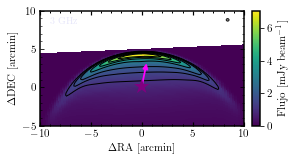

In [25]:
fig1, ax1 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax1.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)
 
# contours
cs = ax1.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)
 
if xs.size:
    ax1.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)
    
# Arrow from star
ax1.annotate(
    '', xy=(xs, ys), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='#6495ED', lw=1.8),
    zorder=6,
)

ax1.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)
 
# Star marker
ax1.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)
 
# elipse del haz sintético, esquina superior derecha
xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92  # posición en fracción de los ejes
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax1.add_patch(beam)
 
# etiqueta "3 GHz"
ax1.text(0.05, 0.9, '3 GHz', transform=ax1.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
# ----------------------------------------------------------------------
# Ejes, límites, aspecto
# ----------------------------------------------------------------------
ax1.set_xlim(*xlim)
ax1.set_ylim(*ylim)
ax1.set_xlabel(r'$\Delta$RA [arcmin]')
ax1.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax1.set_aspect((xhi - xlo) / (yhi - ylo) * (15. / 20.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax1.xaxis.set_major_locator(plt.MultipleLocator(5))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax1.yaxis.set_major_locator(plt.MultipleLocator(5))
ax1.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax1.tick_params(which='both', direction='in', top=True, right=True)

# Colorbar con altura igual a la del mapa
fig1.canvas.draw()
pos = ax1.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig1.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig1.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')
 
plt.show()


## 325 MHz

In [26]:
nu_325M_file = '../../../output/SW_conv_325MHzabs_BD+43.dat'

In [27]:
contour_levels = [44., 54., 64.]
contour_red = [74., 84.]
 
xlim = (-10, 10)
ylim = (-5, 10)
 
siz_x = 77. / 60.0
siz_y = 54. / 60.0

In [28]:
X, Y, Z = load_gridded_data(nu_325M_file)
Xr, Yr = rotate(X, Y, ang, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])

xs, ys = xs*np.cos(incli), ys*np.cos(incli)    
x0_proj_corr = R0_proj_BD43 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD43 * np.cos(ang_corr)

<ipython-input-29-c514796de10d>:10: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax2.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


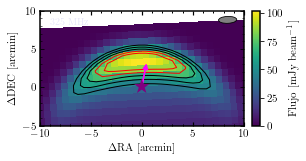

In [29]:
fig2, ax2 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax2.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)

cs = ax2.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)
cs_red = ax2.contour(Xr, Yr, Z, levels=contour_red, colors='red', linewidths=1.)

if xs.size:
    ax2.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax2.annotate(
    '', xy=(xs, ys), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='#6495ED', lw=1.8),
    zorder=6,
)

ax2.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax2.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)
 
xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92  # posición en fracción de los ejes
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax2.add_patch(beam)
 
ax2.text(0.05, 0.9, '325 MHz', transform=ax2.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
# ----------------------------------------------------------------------
# Axes
# ----------------------------------------------------------------------
ax2.set_xlim(*xlim)
ax2.set_ylim(*ylim)
ax2.set_xlabel(r'$\Delta$RA [arcmin]')
ax2.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax2.set_aspect((xhi - xlo) / (yhi - ylo) * (15. / 20.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax2.xaxis.set_major_locator(plt.MultipleLocator(5))
ax2.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax2.yaxis.set_major_locator(plt.MultipleLocator(5))
ax2.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax2.tick_params(which='both', direction='in', top=True, right=True)

fig2.canvas.draw()
pos = ax2.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig2.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig2.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


## Avg 4-12 GHz

In [30]:
nu_avg_file = '../../../output/SW_conv_avgabs_BD+43.dat'

In [31]:
contour_levels = [0.3, 0.6, 0.9]
contour_red = [1.8]
 
xlim = (-10, 10)
ylim = (-5, 10)

siz_x = 10. / 60.0
siz_y = 20. / 60.0

In [32]:
X, Y, Z = load_gridded_data(nu_avg_file)
Xr, Yr = rotate(X, Y, ang, sign=+1)

try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])

xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD43 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD43 * np.cos(ang_corr)

<ipython-input-33-a6fbc3740cc3>:10: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax3.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


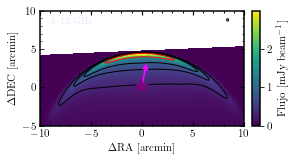

In [33]:
fig3, ax3 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax3.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)

cs = ax3.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)
cs_red = ax3.contour(Xr, Yr, Z, levels=contour_red, colors='red', linewidths=1.)

if xs.size:
    ax3.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)
    
ax3.annotate(
    '', xy=(xs, ys), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='#6495ED', lw=1.8),
    zorder=6,
)

ax3.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax3.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)

xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92 
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax3.add_patch(beam)

ax3.text(0.05, 0.9, '4--12 GHz', transform=ax3.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
# ----------------------------------------------------------------------
# Axes
# ----------------------------------------------------------------------
ax3.set_xlim(*xlim)
ax3.set_ylim(*ylim)
ax3.set_xlabel(r'$\Delta$RA [arcmin]')
ax3.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax3.set_aspect((xhi - xlo) / (yhi - ylo) * (15. / 20.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax3.xaxis.set_major_locator(plt.MultipleLocator(5))
ax3.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax3.yaxis.set_major_locator(plt.MultipleLocator(5))
ax3.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax3.tick_params(which='both', direction='in', top=True, right=True)

fig3.canvas.draw()
pos = ax3.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig3.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig3.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


## 150 MHz

In [34]:
nu_150_file = '../../../output/SW_conv_150MHzabs_BD+43.dat'

In [35]:
contour_levels = [10.]
contour_red = [20., 40., 80., 120.]
 
xlim = (-10, 10)
ylim = (-5, 10)

siz_x = 25. / 60.0
siz_y = 25. / 60.0

In [36]:
X, Y, Z = load_gridded_data(nu_150_file)
Xr, Yr = rotate(X, Y, ang, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])

xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD43 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD43 * np.cos(ang_corr)

<ipython-input-37-a5cb4140d40c>:10: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax4.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


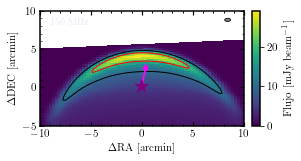

In [37]:
fig4, ax4 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax4.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)

cs = ax4.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)
cs_red = ax4.contour(Xr, Yr, Z, levels=contour_red, colors='red', linewidths=1.)

if xs.size:
    ax4.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax4.annotate(
    '', xy=(xs, ys), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='#6495ED', lw=1.8),
    zorder=6,
)

ax4.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax4.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)

xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax4.add_patch(beam)
 
ax4.text(0.05, 0.9, '150 MHz', transform=ax4.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
ax4.set_xlim(*xlim)
ax4.set_ylim(*ylim)
ax4.set_xlabel(r'$\Delta$RA [arcmin]')
ax4.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax4.set_aspect((xhi - xlo) / (yhi - ylo) * (15. / 20.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax4.xaxis.set_major_locator(plt.MultipleLocator(5))
ax4.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax4.yaxis.set_major_locator(plt.MultipleLocator(5))
ax4.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax4.tick_params(which='both', direction='in', top=True, right=True)

fig4.canvas.draw()
pos = ax4.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig4.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig4.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


In [ ]:
nu_150_unique_file = '../../../output/SW_conv_150MHzabs_BD+43_unique.dat'

In [ ]:
X, Y, Z = load_gridded_data(nu_150_unique_file)
Xr, Yr = rotate(X, Y, ang, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])*np.cos(incli)
    
xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD43 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD43 * np.cos(ang_corr)

In [ ]:
fig5, ax5 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax5.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)

cs = ax5.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)
cs_red = ax5.contour(Xr, Yr, Z, levels=contour_red, colors='red', linewidths=1.)
 
if xs.size:
    ax5.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax5.annotate(
    '', xy=(xs, ys), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='#6495ED', lw=1.8),
    zorder=6,
)

ax5.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax5.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)

xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax5.add_patch(beam)
 
ax5.text(0.05, 0.9, '150 MHz', transform=ax5.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
ax5.set_xlim(*xlim)
ax5.set_ylim(*ylim)
ax5.set_xlabel(r'$\Delta$RA [arcmin]')
ax5.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax5.set_aspect((xhi - xlo) / (yhi - ylo) * (15. / 20.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax5.xaxis.set_major_locator(plt.MultipleLocator(5))
ax5.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax5.yaxis.set_major_locator(plt.MultipleLocator(5))
ax5.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax5.tick_params(which='both', direction='in', top=True, right=True)

fig5.canvas.draw()
pos = ax5.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig5.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig5.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


# Save figs

In [ ]:
from matplotlib.transforms import Bbox

def tight_bbox(fig, pad=0.01):
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    return bbox.padded(pad)

bbox1 = tight_bbox(fig1)
bbox2 = tight_bbox(fig2)
bbox3 = tight_bbox(fig3)
bbox4 = tight_bbox(fig4)
bbox5 = tight_bbox(fig5)

common_bbox = Bbox.union([bbox1, bbox2, bbox3, bbox4, bbox5])

#fig1.savefig('map_BD+43_3G.pdf',   bbox_inches=common_bbox)
#fig2.savefig('map_BD+43_325M.pdf', bbox_inches=common_bbox)
#fig3.savefig('map_BD+43_avg.pdf',  bbox_inches=common_bbox)
#fig4.savefig('map_BD+43_150M.pdf',  bbox_inches=common_bbox)
#fig5.savefig('map_BD+43_150M_unique.pdf',  bbox_inches=common_bbox)